# Data Visualization with Matplotlib (and Seaborn)
**MATH 153 · Data Wrangling and Data Engineering**
Moussa Doumbia, Ph.D. — Department of Mathematics, Howard University

### What you will learn
1. How a Matplotlib figure is built: **figure** and **axes**.
2. The core charts: **histogram, bar plot, scatter plot, line plot, box plot**.
3. Several charts in one figure with **subplots**.
4. Seaborn's one-line statistical charts: **pairplot, jointplot, countplot, heatmap**.
5. How to **choose** the right chart, and the most common mistakes.

> **The big idea.** Every chart answers a question. First decide the question (*how is age distributed?
> do women survive more often?*), then pick the chart that answers it. The question decides the chart, not the other way around.

**Matplotlib vs Seaborn.** Matplotlib is the drawing engine: full control, more typing. Seaborn is built *on top of*
Matplotlib: one line for common statistical charts. `pairplot` and `jointplot` are **Seaborn** functions.

## 0. Setup and data

In [29]:
pwd

'/Users/moussadoumbia/Desktop/2026_into_DS_02'

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
# A clean, readable default style
plt.rcParams.update({
    "figure.figsize": (8, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titleweight": "bold",
    "font.size": 11,
})

# # A small, colorblind-friendly set of colors, used in the same order everywhere
# BLUE, ORANGE, GREEN = "#2a78d6", "#eb6834", "#1baf7a"

**The data.** We use a Titanic-style passenger dataset: one row per passenger. The cell below *generates* it, so the
notebook runs anywhere without downloading anything. If you have the real `titanic.csv`, use the line that is commented
out instead; every chart below works the same way.

In [2]:
df= sns.load_dataset("titanic")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [38]:
PAL = {"Did not survive": 'orange', "Survived": 'blue'}      # same color for the same group, everywhere
ORDER = ["Did not survive", "Survived"]


---
## 1. Anatomy of a Matplotlib chart

* A **Figure** is the whole picture (the canvas).
* An **Axes** is one chart inside it: its own x-axis, y-axis, title, and data.

The recommended way to start every chart is `fig, ax = plt.subplots()`. Then you draw *on* `ax` and label it.

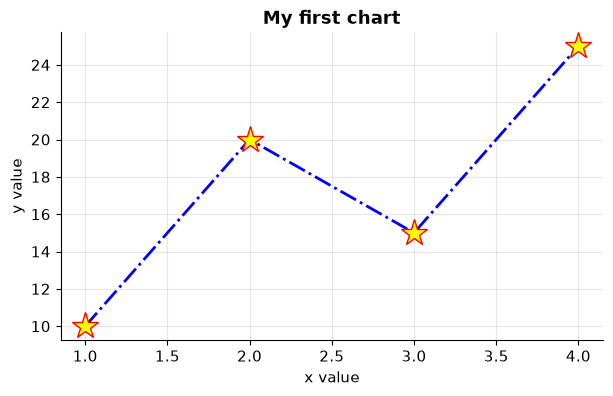

In [49]:
fig, ax = plt.subplots(figsize=(7, 4))          # 1. create the figure and one axes
ax.plot([1, 2, 3, 4], [10, 20, 15, 25],         # 2. draw on the axes
        color='blue', marker="*", lw=2, markerfacecolor='yellow',markeredgecolor='red', markersize=20,ls='-.' )
ax.set_title("My first chart")                  # 3. label everything
ax.set_xlabel("x value")
ax.set_ylabel("y value")
plt.show()                                      # 4. display

> **Two styles.** You will also see `plt.plot(...)`, `plt.title(...)`. That shortcut style draws on "the current axes".
> It is fine for one quick chart, but `fig, ax` is clearer as soon as you have more than one chart. We use `ax` below.

---
## 2. Histogram: how is a **numeric** column distributed?

A histogram cuts the range of a number into **bins** and counts how many values fall in each.
Use it for numeric columns such as `Age` or `Fare`, not for categories like `Sex`.

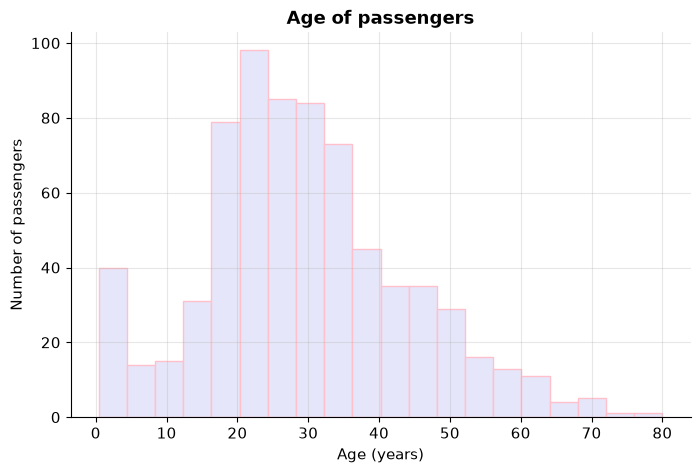

In [51]:
fig, ax = plt.subplots()
ax.hist(df["age"].dropna(), bins=20, color='lavender', edgecolor="pink")
ax.set_title("Age of passengers")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Number of passengers")
plt.show()

**Notes**
* `.dropna()` removes missing ages first; a histogram cannot place a missing value in a bin.
* `edgecolor="white"` draws a thin gap between bars so they are easy to tell apart.

**The number of bins changes the story.** Too few bins hide the shape; too many make noise.

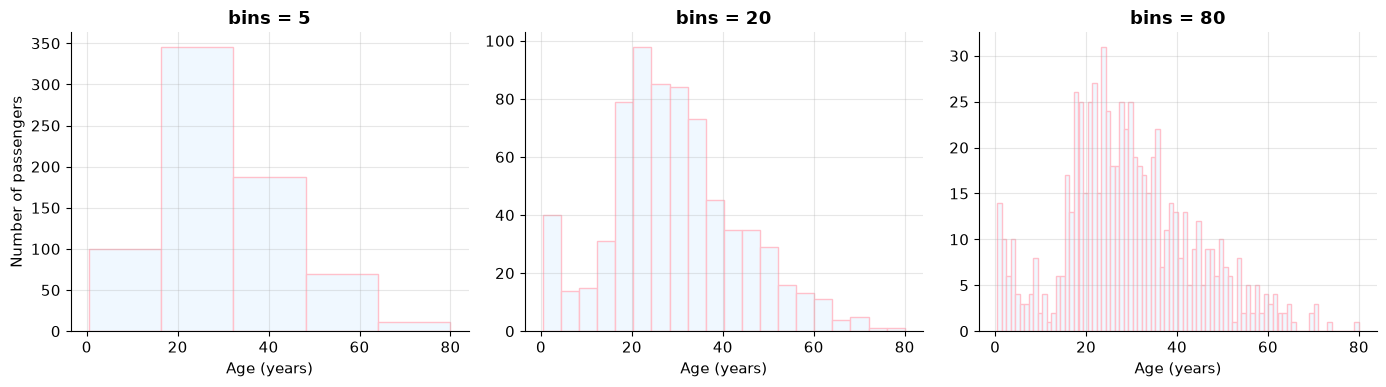

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=False)
for ax, b in zip(axes, [5, 20, 80]):
    ax.hist(df["age"].dropna(), bins=b, color='aliceblue', edgecolor="pink")
    ax.set_title(f"bins = {b}")
    ax.set_xlabel("Age (years)")
axes[0].set_ylabel("Number of passengers")
plt.tight_layout()
plt.show()

**Comparing two groups.** Draw two histograms on the same axes with the **same bins**. Drawing them as outlines
(`histtype="step"`) keeps both shapes visible; two filled, see-through histograms mix into a muddy third color.

In [ ]:
bins = np.arange(0, 85, 5)                       # the SAME bins for both groups
fig, ax = plt.subplots()
ax.hist(df.loc[df["survived"] == 0, "age"].dropna(), bins=bins, histtype="step",
        linewidth=2.5, color='orange', label="Did not survive")
ax.hist(df.loc[df["survived"] == 1, "age"].dropna(), bins=bins, histtype="step",
        linewidth=2.5, color='blue', label="Survived")
ax.set_title("Age by survival")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Number of passengers")
ax.legend()
plt.show()

---
## 3. Bar plot: compare **categories**

For a category (`Sex`, `Pclass`, `Embarked`), first **count** or **summarize**, then draw one bar per category.

sex
male      577
female    314
Name: count, dtype: int64


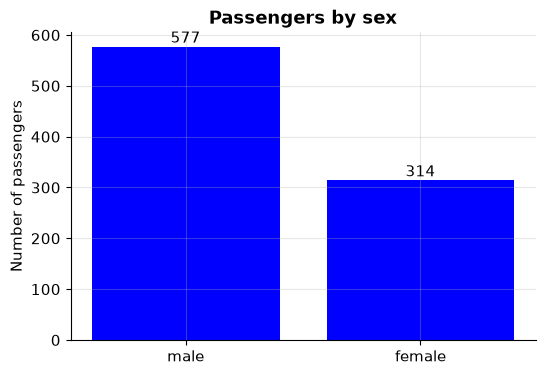

In [60]:
counts = df["sex"].value_counts()               # count first
print(counts)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(counts.index, counts.values, color='blue')
ax.set_title("Passengers by sex")
ax.set_ylabel("Number of passengers")
for i, v in enumerate(counts.values):           # label each bar with its value
    ax.text(i, v + 8, str(v), ha="center")
plt.show()

**Bars for a summary, not just a count:** the survival **rate** per class (the mean of a 0/1 column is a proportion).

pclass
1    0.630
2    0.473
3    0.242
Name: survived, dtype: float64


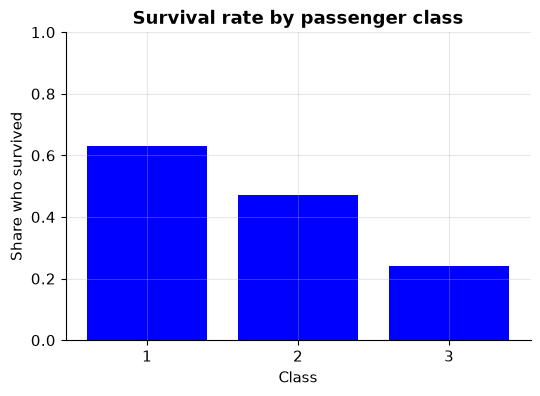

In [61]:
rate = df.groupby("pclass")["survived"].mean()
print(rate.round(3))

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(rate.index.astype(str), rate.values, color='blue')
ax.set_title("Survival rate by passenger class")
ax.set_xlabel("Class")
ax.set_ylabel("Share who survived")
ax.set_ylim(0, 1)                               # a rate lives between 0 and 1
plt.show()

**Grouped bars: two categories at once.** `pd.crosstab` builds the table of counts, and pandas' `.plot(kind="bar")`
(which uses Matplotlib underneath) draws one group of bars per row.

        Did not survive  Survived
Sex                              
female               79       247
male                426       139


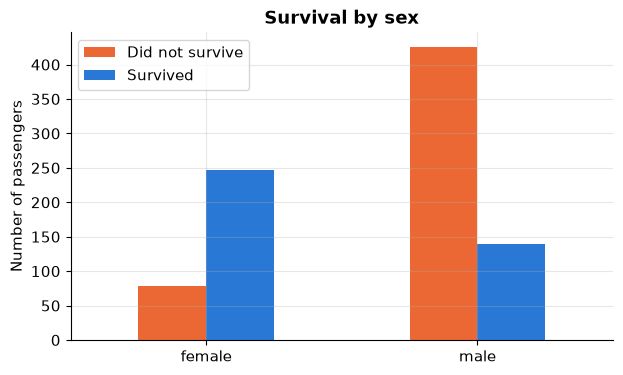

In [10]:
table = pd.crosstab(df["Sex"], df["Survived"])
table.columns = ["Did not survive", "Survived"]
print(table)

ax = table.plot(kind="bar", color=[ORANGE, BLUE], figsize=(7, 4), rot=0)
ax.set_title("Survival by sex")
ax.set_xlabel("")
ax.set_ylabel("Number of passengers")
plt.show()

**Horizontal bars** are easier to read when category names are long or there are many categories. Sort them.

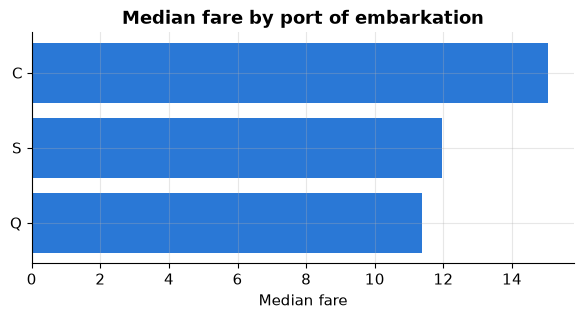

In [11]:
fare_by_port = df.groupby("Embarked")["Fare"].median().sort_values()
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(fare_by_port.index, fare_by_port.values, color=BLUE)
ax.set_title("Median fare by port of embarkation")
ax.set_xlabel("Median fare")
plt.show()

---
## 4. Scatter plot: the relationship between **two numbers**

One dot per row: x = one column, y = another. Color can add a third variable (a category).

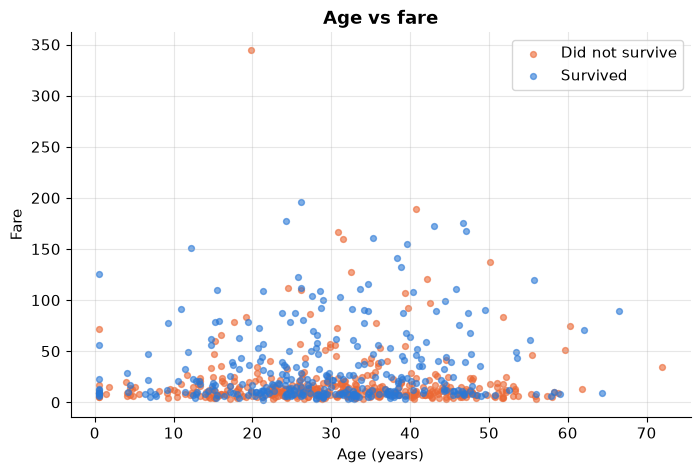

In [12]:
fig, ax = plt.subplots()
for value, color, label in [(0, ORANGE, "Did not survive"), (1, BLUE, "Survived")]:
    part = df[df["Survived"] == value]
    ax.scatter(part["Age"], part["Fare"], s=18, alpha=0.6, color=color, label=label)
ax.set_title("Age vs fare")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Fare")
ax.legend()
plt.show()

**Skewed data: use a log scale.** Most fares are small and a few are very large, so the dots pile up at the bottom.
`ax.set_yscale("log")` spreads them out (each step up the axis is ×10).

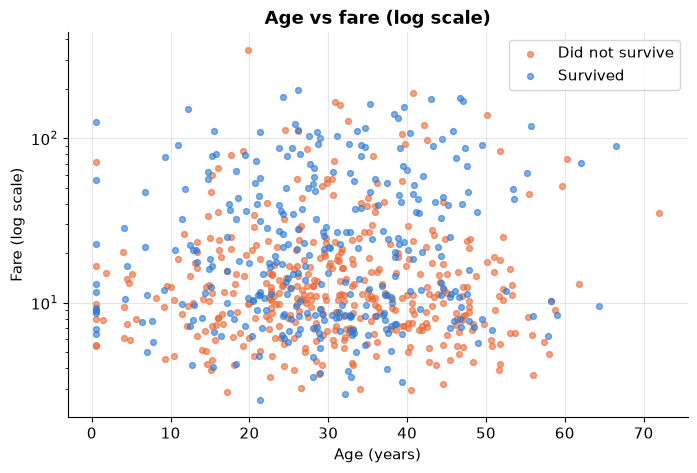

In [13]:
fig, ax = plt.subplots()
for value, color, label in [(0, ORANGE, "Did not survive"), (1, BLUE, "Survived")]:
    part = df[df["Survived"] == value]
    ax.scatter(part["Age"], part["Fare"], s=18, alpha=0.6, color=color, label=label)
ax.set_yscale("log")
ax.set_title("Age vs fare (log scale)")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Fare (log scale)")
ax.legend()
plt.show()

---
## 5. Line plot: a value that changes along an **ordered** axis

Lines connect points, so the x-axis must have a meaningful order (time, age bands, steps). Here: the survival rate by
age band, built with `pd.cut` from Week 6.

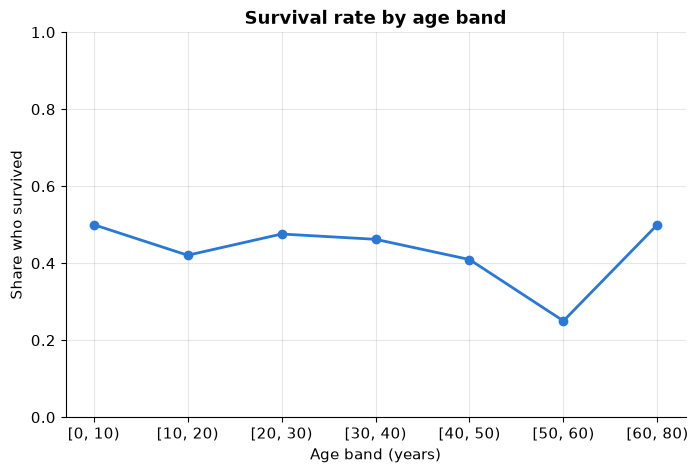

In [14]:
bands = pd.cut(df["Age"], bins=[0, 10, 20, 30, 40, 50, 60, 80], right=False)
by_band = df.groupby(bands, observed=True)["Survived"].mean()

fig, ax = plt.subplots()
ax.plot(by_band.index.astype(str), by_band.values, marker="o", color=BLUE, linewidth=2)
ax.set_title("Survival rate by age band")
ax.set_xlabel("Age band (years)")
ax.set_ylabel("Share who survived")
ax.set_ylim(0, 1)
plt.show()

---
## 6. Box plot: compare **distributions** across groups

A box shows the median (middle line), the quartiles Q1 and Q3 (the box), the whiskers (up to 1.5 × IQR), and the
points beyond them, which are the **IQR outliers** from Week 5.

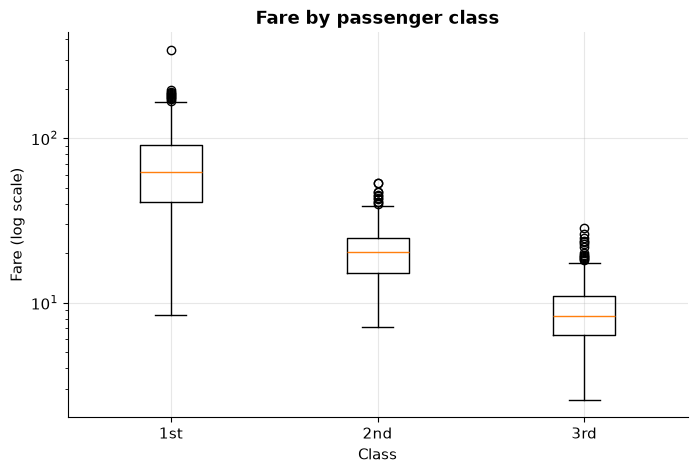

In [15]:
groups = [df.loc[df["Pclass"] == c, "Fare"] for c in [1, 2, 3]]
fig, ax = plt.subplots()
ax.boxplot(groups, tick_labels=["1st", "2nd", "3rd"])
ax.set_yscale("log")
ax.set_title("Fare by passenger class")
ax.set_xlabel("Class")
ax.set_ylabel("Fare (log scale)")
plt.show()

> If your Matplotlib is older than 3.9 and `tick_labels` gives an error, use `labels=` instead.

---
## 7. Several charts in one figure: `plt.subplots(rows, cols)`

`plt.subplots(2, 2)` returns a 2 × 2 grid of axes. You pick a chart by its position: `axes[row, col]`.

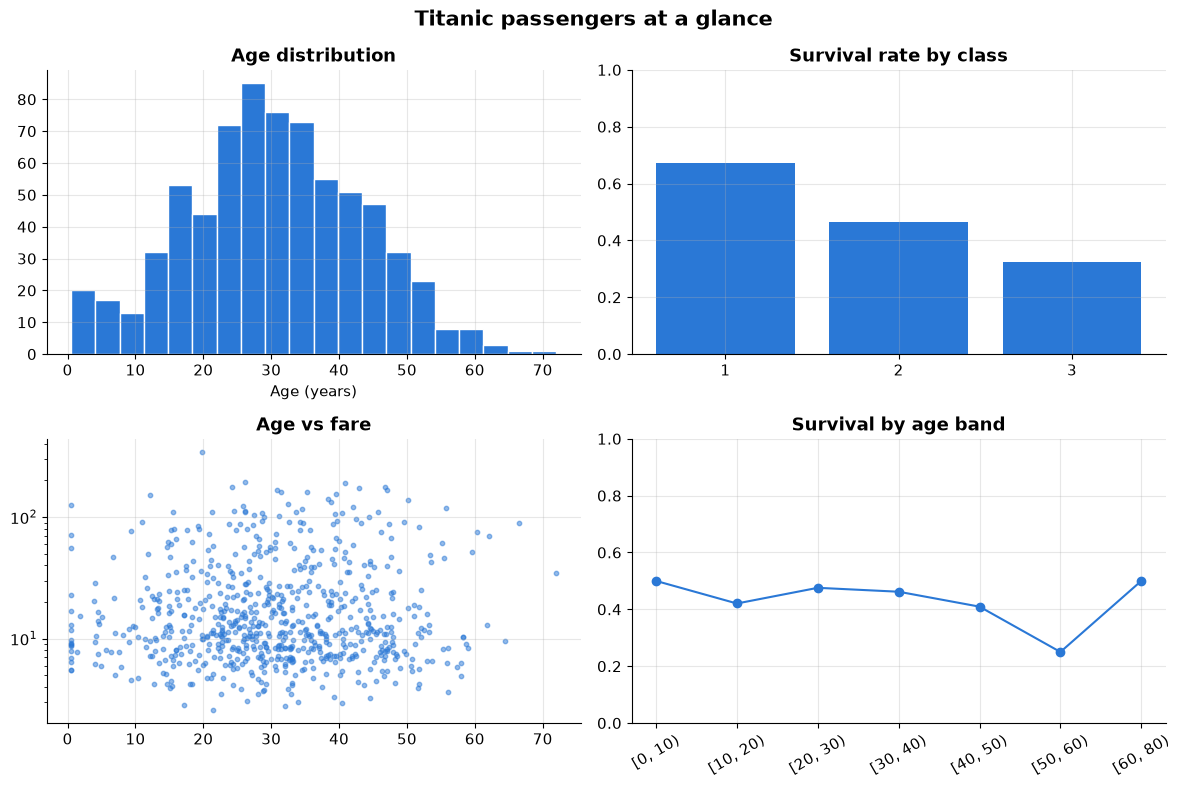

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].hist(df["Age"].dropna(), bins=20, color=BLUE, edgecolor="white")
axes[0, 0].set_title("Age distribution")
axes[0, 0].set_xlabel("Age (years)")

axes[0, 1].bar(rate.index.astype(str), rate.values, color=BLUE)
axes[0, 1].set_title("Survival rate by class")
axes[0, 1].set_ylim(0, 1)

axes[1, 0].scatter(df["Age"], df["Fare"], s=10, alpha=0.5, color=BLUE)
axes[1, 0].set_yscale("log")
axes[1, 0].set_title("Age vs fare")

axes[1, 1].plot(by_band.index.astype(str), by_band.values, marker="o", color=BLUE)
axes[1, 1].set_title("Survival by age band")
axes[1, 1].set_ylim(0, 1)
axes[1, 1].tick_params(axis="x", rotation=30)

fig.suptitle("Titanic passengers at a glance", fontsize=15, fontweight="bold")
plt.tight_layout()           # stops titles and labels from overlapping
plt.show()

---
## 8. Seaborn: statistical charts in one line

Seaborn works directly with a DataFrame: you pass `data=df` and the **column names**. Its `hue=` option colors by a
category automatically. (`hue` exists only in Seaborn; `plt.hist(..., hue=...)` is an error.) We color by the
`Outcome` column, the readable version of `Survived`, so the legends say *Survived* instead of *1*.

### 8.1 `countplot`: counts per category, split by another category

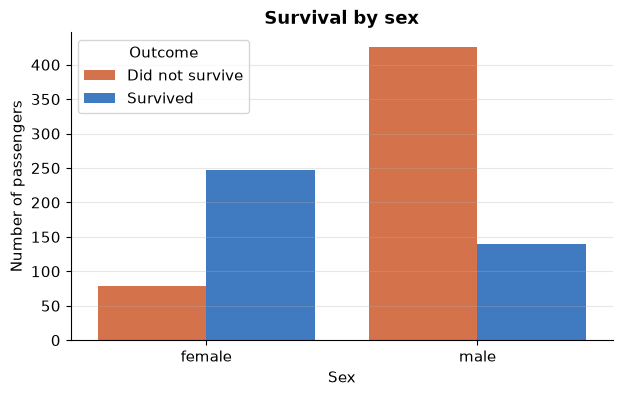

In [17]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df, x="Sex", hue="Outcome", hue_order=ORDER, palette=PAL, ax=ax)
ax.set_title("Survival by sex")
ax.set_ylabel("Number of passengers")
plt.show()

### 8.2 `histplot` with `hue`: the Section 2 overlay, in one line

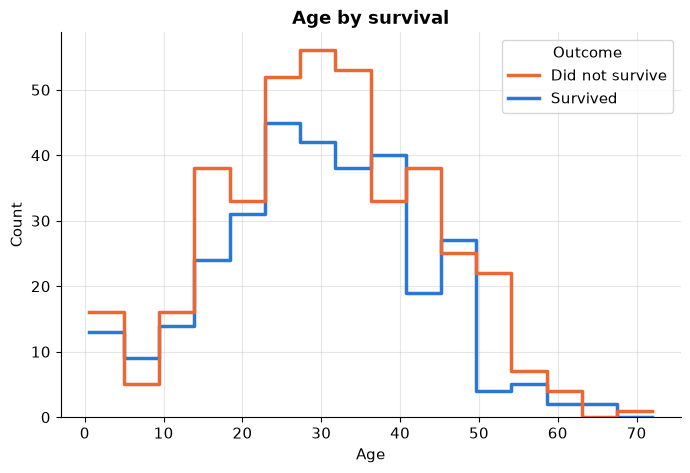

In [18]:
fig, ax = plt.subplots()
sns.histplot(data=df, x="Age", hue="Outcome", hue_order=ORDER, bins=16, palette=PAL,
             element="step", fill=False, linewidth=2.5, ax=ax)
ax.set_title("Age by survival")
plt.show()

### 8.3 `jointplot`: one relationship + each variable's distribution

The middle shows the scatter plot of two variables; the top and right margins show each variable's distribution,
one curve per group.

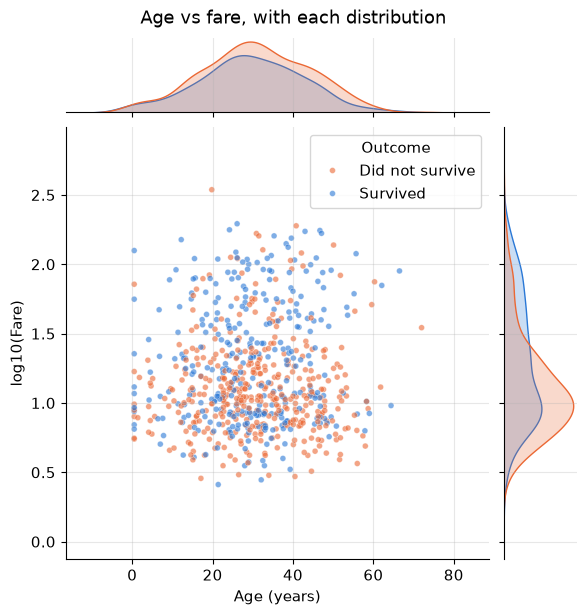

In [19]:
# Fare is very skewed, so plot log10(Fare): 1 = a fare of 10, 2 = a fare of 100
jp = df.assign(log10_fare=np.log10(df["Fare"]))
g = sns.jointplot(data=jp, x="Age", y="log10_fare", hue="Outcome", hue_order=ORDER, palette=PAL,
                  height=6, joint_kws={"s": 18, "alpha": 0.6})
g.set_axis_labels("Age (years)", "log10(Fare)")
g.figure.suptitle("Age vs fare, with each distribution", y=1.02)
plt.show()

### 8.4 `pairplot`: every pair of numeric columns at once

A grid of scatter plots for every pair of columns, with each column's distribution on the diagonal.
It is a fast way to **explore** a new dataset. Keep it to a few columns: 4 columns already make 16 panels.

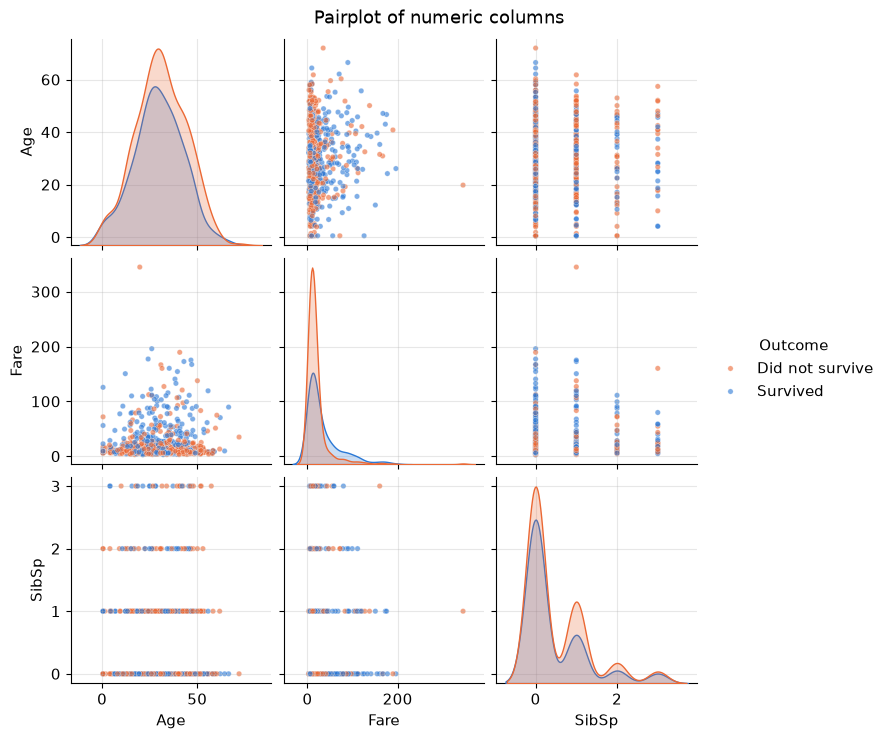

In [20]:
g = sns.pairplot(df[["Age", "Fare", "SibSp", "Outcome"]].dropna(),
                 hue="Outcome", hue_order=ORDER, palette=PAL, height=2.4, plot_kws={"s": 15, "alpha": 0.6})
g.figure.suptitle("Pairplot of numeric columns", y=1.02)
plt.show()

### 8.5 `heatmap`: a correlation matrix

Correlations go from −1 to +1, so use a **diverging** color map centered at 0: one color for negative, another for
positive, and white for "no relationship".

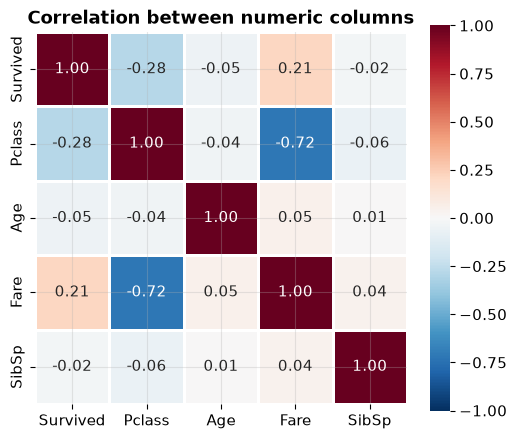

In [21]:
num = df[["Survived", "Pclass", "Age", "Fare", "SibSp"]]
corr = num.corr()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            square=True, linewidths=1, ax=ax)
ax.set_title("Correlation between numeric columns")
plt.show()

**Read it:** `Pclass` and `Fare` are strongly negative (1st class = high fare), and `Survived` and `Pclass` are
negative (a *lower* class number, i.e. 1st class, goes with *more* survival).

---
## 9. Saving a figure

Save **before** `plt.show()`. Use `dpi` for sharpness and `bbox_inches="tight"` to avoid cut-off labels.

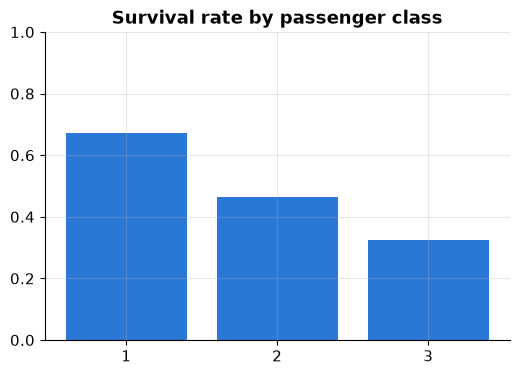

saved: survival_by_class.png


In [22]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(rate.index.astype(str), rate.values, color=BLUE)
ax.set_title("Survival rate by passenger class")
ax.set_ylim(0, 1)
fig.savefig("survival_by_class.png", dpi=200, bbox_inches="tight")
plt.show()
print("saved: survival_by_class.png")

---
## 10. Choosing the right chart

| Question | Chart | Matplotlib / Seaborn |
|---|---|---|
| How is **one number** distributed? | Histogram | `ax.hist`, `sns.histplot` |
| How do **categories** compare? | Bar plot | `ax.bar`, `ax.barh`, `sns.countplot` |
| How are **two numbers** related? | Scatter plot | `ax.scatter`, `sns.jointplot` |
| How does a value change **in order** (time, bands)? | Line plot | `ax.plot` |
| How do **distributions** compare across groups? | Box plot | `ax.boxplot`, `sns.boxplot` |
| First look at **many numbers** at once? | Pair plot | `sns.pairplot` |
| Which numbers **move together**? | Heatmap of correlations | `sns.heatmap(df.corr())` |

### Common mistakes

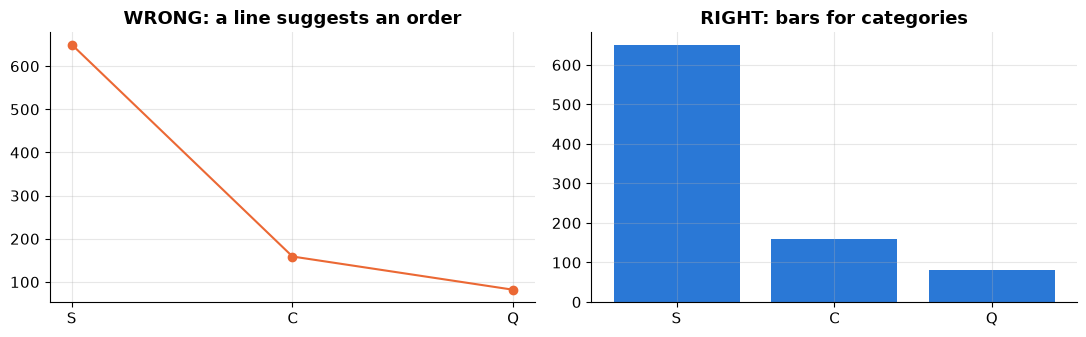

In [23]:
# Mistake 1: hue in Matplotlib, and a category in a histogram.
# plt.hist(df["Sex"], df["Survived"], hue=df["Sex"])
#   -> the 2nd argument of plt.hist is BINS, and hue does not exist in Matplotlib.
# Fix: count the category, then draw bars (Section 3), or use sns.countplot (Section 8.1).

# Mistake 2: a line plot for categories that have no order.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
port_counts = df["Embarked"].value_counts()
axes[0].plot(port_counts.index, port_counts.values, marker="o", color=ORANGE)
axes[0].set_title("WRONG: a line suggests an order")
axes[1].bar(port_counts.index, port_counts.values, color=BLUE)
axes[1].set_title("RIGHT: bars for categories")
plt.tight_layout()
plt.show()

More mistakes to avoid:
* **No labels.** Every chart needs a title, axis labels, and units. A reader should not have to guess.
* **Bar charts that do not start at 0.** A bar's *length* is its value; cutting the axis exaggerates differences.
* **Two y-axes on one chart.** Two measures with different scales belong in two charts side by side.
* **Rainbow colors for numbers.** Use one hue from light to dark for "more"; use two hues with white in the middle for "negative vs positive".
* **Too many categories in one chart.** Keep the top few and group the rest as "Other".

---
## Practice

**P1.** Draw a histogram of `Fare`. Then draw it again with `np.log1p(df["Fare"])`. Which one shows the shape better, and why?

In [24]:
# P1

**P2.** Bar plot of the survival rate by `Embarked` port, sorted from highest to lowest, with the y-axis from 0 to 1.

In [25]:
# P2

**P3.** Scatter plot of `Age` vs `Fare` for **1st-class** passengers only, colored by `Sex`. Add a title, labels, and a legend.

In [26]:
# P3

**P4.** Use `sns.boxplot(data=df, x="Pclass", y="Age")` to compare ages across classes. What do you notice?

In [27]:
# P4

**P5.** Build a 1 × 3 figure with a histogram, a bar plot, and a scatter plot of your choice, then save it as `my_dashboard.png`.

In [28]:
# P5

---
### Remember
* Start with the **question**, then pick the chart.
* `fig, ax = plt.subplots()`, draw on `ax`, then **label everything**.
* Histogram = one number; bar = categories; scatter = two numbers; line = ordered values; box = distributions by group.
* `hue=`, `pairplot`, and `jointplot` are **Seaborn**.